# Lecture 8: Other sources of income, other taxes

The eighth model extends the Armington model of the {doc}`seventh notebook <07_armington>` with income from outside production and two new taxes. Households receive remittances from abroad and transfers from the government. The government receives a transfer from the rest of the world and taxes value added and exports. The assignment compares two ways of raising household income by 100.

:::{admonition} Watch the lectures
:class: tip

- 📺 Lecture: [Computable General Equilibrium models: other sources of revenues, other taxes](https://www.youtube.com/watch?v=WrY_IGEfG6o)
- ✅ Correction: [Computable General Equilibrium model: other sources of income, other taxes - Correction](https://www.youtube.com/watch?v=bfeVzui-lTU)
- 🎓 Full course playlist: [Antoine Bouet's CGE lectures](https://www.youtube.com/playlist?list=PLfV47vAW_jrc57x1O36Pz9vol86f0YUXW)
:::

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cge_modeling as cm

## The economy

Production, trade and the spending rules are unchanged from the seventh notebook. The new flows are:

- Households receive remittances from abroad, paid in foreign currency, and a transfer $transf_{G,hh}$ from the government. Income becomes $INC = W \cdot LS + R \cdot KS + e \cdot remittances$, and disposable income $DISP\_INC = (1 - itr) \cdot INC + transf_{G,hh}$.
- The government receives a transfer $transf_{RoW,G}$ from the rest of the world.
- A value added tax at rate $tva_i$ falls on factor payments, so firms hire capital until $\alpha_i \cdot PVA_i \cdot VA_i = R \cdot KD_i \cdot (1 + tva_i)$, and labor in the same way.
- An export tax at rate $te_i$ separates the producer's export price from the world price, $PX_i \cdot (1 + te_i) = e \cdot PWX_i$.

Remittances and the transfer to the government are income from abroad that the trade balance leaves out. The current account adds them to the trade balance and replaces it in the macroeconomic balance.

### Variables

The current account $curr\_acc$ is the only new variable.

In [2]:
sectors = ["Agr", "Ind", "Serv"]
mod = cm.CGEModel(coords={"i": sectors, "j": sectors})

with mod:
    Y = cm.Variable("Y", dims="i", description="Output of sector <dim:i>")
    VA = cm.Variable("VA", dims="i", description="Value added in sector <dim:i>")
    IC = cm.Variable("IC", dims="i", description="Intermediate bundle used by sector <dim:i>")
    CIJ = cm.Variable("CIJ", dims=("i", "j"), description="Good <dim:i> used by sector <dim:j>")
    KD = cm.Variable("KD", dims="i", description="Capital demand of sector <dim:i>")
    LD = cm.Variable("LD", dims="i", description="Labor demand of sector <dim:i>")
    P = cm.Variable("P", dims="i", description="Consumer price of good <dim:i>")
    PY = cm.Variable("PY", dims="i", description="Producer price of the output of sector <dim:i>")
    PVA = cm.Variable("PVA", dims="i", description="Price of value added in sector <dim:i>")
    PIC = cm.Variable("PIC", dims="i", description="Price of the intermediate bundle in sector <dim:i>")
    DEMTOT = cm.Variable("DEMTOT", dims="i", description="Absorption of good <dim:i>")
    PDEMTOT = cm.Variable("PDEMTOT", dims="i", description="Price of absorption of good <dim:i> before tax")
    D = cm.Variable("D", dims="i", description="Domestic variety of good <dim:i> bought at home")
    PD = cm.Variable("PD", dims="i", description="Domestic price of good <dim:i>")
    XD = cm.Variable("XD", dims="i", description="Domestic sales of sector <dim:i>")
    M = cm.Variable("M", dims="i", description="Imports of good <dim:i>")
    PM = cm.Variable("PM", dims="i", description="Domestic price of imports of good <dim:i>")
    X = cm.Variable("X", dims="i", description="Exports of good <dim:i>")
    PX = cm.Variable("PX", dims="i", description="Domestic price of exports of good <dim:i>")
    PWM = cm.Variable("PWM", dims="i", description="World price of imports of good <dim:i>")
    PWX = cm.Variable("PWX", dims="i", description="World price of exports of good <dim:i>")
    W = cm.Variable("W", description="Wage")
    R = cm.Variable("R", description="Return to capital")
    INC = cm.Variable("INC", description="Gross income of households")
    DISP_INC = cm.Variable("DISP_INC",
                           latex_name=r"\mathrm{DISP\_INC}",
                           description="Disposable income of households")
    savings = cm.Variable("savings", description="Household saving")
    C = cm.Variable("C", dims="i", description="Household consumption of good <dim:i>")
    U = cm.Variable("U", description="Utility of households")
    BUDG_EXP = cm.Variable("BUDG_EXP",
                           latex_name=r"\mathrm{BUDG\_EXP}",
                           description="Government spending")
    CG = cm.Variable("CG", dims="i", description="Government purchases of good <dim:i>")
    INV = cm.Variable("INV", description="Total investment")
    CK = cm.Variable("CK", dims="i", description="Investment demand for good <dim:i>")
    tradesold = cm.Variable("tradesold", description="Trade balance, exports minus imports")
    curr_acc = cm.Variable("curr_acc",
                           latex_name=r"\mathrm{curr\_acc}",
                           description="Current account, the trade balance plus transfers from abroad")
    Leon = cm.Variable("Leon", description="Walras check variable")

mod.summary("variables")

\(\textbf{Symbol}\),\(\textbf{Description}\)
\(Y_{i}\),\(\text{Output}\) \(\text{of}\) \(\text{sector}\) \(\text{i}\)
\(\mathrm{VA}_{i}\),\(\text{Value}\) \(\text{added}\) \(\text{in}\) \(\text{sector}\) \(\text{i}\)
\(\mathrm{IC}_{i}\),\(\text{Intermediate}\) \(\text{bundle}\) \(\text{used}\) \(\text{by}\) \(\text{sector}\) \(\text{i}\)
"\(\mathrm{CIJ}_{i, j}\)",\(\text{Good}\) \(\text{i}\) \(\text{used}\) \(\text{by}\) \(\text{sector}\) \(\text{j}\)
\(\mathrm{KD}_{i}\),\(\text{Capital}\) \(\text{demand}\) \(\text{of}\) \(\text{sector}\) \(\text{i}\)
\(\mathrm{LD}_{i}\),\(\text{Labor}\) \(\text{demand}\) \(\text{of}\) \(\text{sector}\) \(\text{i}\)
\(P_{i}\),\(\text{Consumer}\) \(\text{price}\) \(\text{of}\) \(\text{good}\) \(\text{i}\)
\(\mathrm{PY}_{i}\),\(\text{Producer}\) \(\text{price}\) \(\text{of}\) \(\text{the}\) \(\text{output}\) \(\text{of}\) \(\text{sector}\) \(\text{i}\)
\(\mathrm{PVA}_{i}\),\(\text{Price}\) \(\text{of}\) \(\text{value}\) \(\text{added}\) \(\text{in}\) \(\text{sector}\) \(\text{i}\)
\(\mathrm{PIC}_{i}\),\(\text{Price}\) \(\text{of}\) \(\text{the}\) \(\text{intermediate}\) \(\text{bundle}\) \(\text{in}\) \(\text{sector}\) \(\text{i}\)


### Parameters

The new parameters are the three transfers and the two tax rates, $tva_i$ and $te_i$.

In [3]:
with mod:
    alpha = cm.Parameter("alpha", dims="i", description="Capital share of value added in sector <dim:i>")
    A = cm.Parameter("A", dims="i", description="Productivity in sector <dim:i>")
    psi_VA = cm.Parameter("psi_VA", dims="i", description="Value added per unit of output in sector <dim:i>")
    psi_IC = cm.Parameter("psi_IC", dims="i", description="Intermediate bundle per unit of output in sector <dim:i>")
    psi_IJC = cm.Parameter("psi_IJC",
                           dims=("i", "j"),
                           description="Good <dim:i> per unit of the intermediate bundle of sector <dim:j>")
    gamma = cm.Parameter("gamma", dims="i", description="Household budget share of good <dim:i>")
    alpha_g = cm.Parameter("alpha_g",
                           dims="i",
                           latex_name=r"\alpha^G",
                           description="Government budget share of good <dim:i>")
    alpha_k = cm.Parameter("alpha_k",
                           dims="i",
                           latex_name=r"\alpha^K",
                           description="Investment budget share of good <dim:i>")
    mps = cm.Parameter("mps", description="Marginal propensity to save")
    itr = cm.Parameter("itr", description="Income tax rate")
    tau = cm.Parameter("tau", dims="i", description="Indirect tax rate on absorption of good <dim:i>")
    tm = cm.Parameter("tm", dims="i", description="Import duty rate on good <dim:i>")
    te = cm.Parameter("te", dims="i", description="Export tax rate on good <dim:i>")
    tva = cm.Parameter("tva", dims="i", description="Value added tax rate in sector <dim:i>")
    a_d = cm.Parameter("a_d",
                       dims="i",
                       latex_name="a^D",
                       description="Share parameter of the domestic variety of good <dim:i>")
    a_m = cm.Parameter("a_m",
                       dims="i",
                       latex_name="a^M",
                       description="Share parameter of imports of good <dim:i>")
    a_xd = cm.Parameter("a_xd",
                        dims="i",
                        latex_name="a^{XD}",
                        description="Share parameter of domestic sales of sector <dim:i>")
    a_x = cm.Parameter("a_x",
                       dims="i",
                       latex_name="a^X",
                       description="Share parameter of exports of sector <dim:i>")
    sigma_arm = cm.Parameter("sigma_arm",
                             dims="i",
                             latex_name=r"\sigma^{arm}",
                             description="Elasticity of substitution between domestic and imported good <dim:i>")
    sigma_cet = cm.Parameter("sigma_cet",
                             dims="i",
                             latex_name=r"\sigma^{cet}",
                             description="Elasticity of transformation between domestic sales and exports of sector <dim:i>")
    f_m = cm.Parameter("f_m",
                       dims="i",
                       latex_name="f^M",
                       description="Scale of the rest of the world's supply of good <dim:i>")
    f_x = cm.Parameter("f_x",
                       dims="i",
                       latex_name="f^X",
                       description="Scale of the rest of the world's demand for good <dim:i>")
    sigma_m = cm.Parameter("sigma_m",
                           dims="i",
                           latex_name=r"\sigma^M",
                           description="Price elasticity of the rest of the world's supply of good <dim:i>")
    sigma_x = cm.Parameter("sigma_x",
                           dims="i",
                           latex_name=r"\sigma^X",
                           description="Price elasticity of the rest of the world's demand for good <dim:i>")
    remittances = cm.Parameter("remittances", description="Remittances to households, in foreign currency")
    transf_G_hh = cm.Parameter("transf_G_hh",
                               latex_name=r"transf_{G,hh}",
                               description="Transfer from the government to households")
    transf_RoW_G = cm.Parameter("transf_RoW_G",
                                latex_name=r"transf_{RoW,G}",
                                description="Transfer from the rest of the world to the government, in foreign currency")
    e = cm.Parameter("e", description="Exchange rate")
    pubsold = cm.Parameter("pubsold", description="Public balance, revenue minus spending")
    LS = cm.Parameter("LS", description="Labor supply")
    KS = cm.Parameter("KS", description="Capital supply")
    PD_Agr = cm.Parameter("PD_Agr",
                          latex_name=r"\bar{PD}_{Agr}",
                          description="Domestic price of agriculture, the numeraire")

mod.summary("parameters")

\(\textbf{Symbol}\),\(\textbf{Description}\)
\(\alpha_{i}\),\(\text{Capital}\) \(\text{share}\) \(\text{of}\) \(\text{value}\) \(\text{added}\) \(\text{in}\) \(\text{sector}\) \(\text{i}\)
\(A_{i}\),\(\text{Productivity}\) \(\text{in}\) \(\text{sector}\) \(\text{i}\)
"\(\psi_{\mathrm{VA}, i}\)",\(\text{Value}\) \(\text{added}\) \(\text{per}\) \(\text{unit}\) \(\text{of}\) \(\text{output}\) \(\text{in}\) \(\text{sector}\) \(\text{i}\)
"\(\psi_{\mathrm{IC}, i}\)",\(\text{Intermediate}\) \(\text{bundle}\) \(\text{per}\) \(\text{unit}\) \(\text{of}\) \(\text{output}\) \(\text{in}\) \(\text{sector}\) \(\text{i}\)
"\(\psi_{\mathrm{IJC}, i, j}\)",\(\text{Good}\) \(\text{i}\) \(\text{per}\) \(\text{unit}\) \(\text{of}\) \(\text{the}\) \(\text{intermediate}\) \(\text{bundle}\) \(\text{of}\) \(\text{sector}\) \(\text{j}\)
\(\gamma_{i}\),\(\text{Household}\) \(\text{budget}\) \(\text{share}\) \(\text{of}\) \(\text{good}\) \(\text{i}\)
\(\alpha^G_{i}\),\(\text{Government}\) \(\text{budget}\) \(\text{share}\) \(\text{of}\) \(\text{good}\) \(\text{i}\)
\(\alpha^K_{i}\),\(\text{Investment}\) \(\text{budget}\) \(\text{share}\) \(\text{of}\) \(\text{good}\) \(\text{i}\)
\(\mathrm{mps}\),\(\text{Marginal}\) \(\text{propensity}\) \(\text{to}\) \(\text{save}\)
\(\mathrm{itr}\),\(\text{Income}\) \(\text{tax}\) \(\text{rate}\)


### Equations

Seven equations change and one is new. Income and disposable income add the transfers to households. The capital and labor demands carry the VAT wedge, and the export price carries the export tax. The public balance adds the transfer from abroad, the VAT and the export tax to revenue, and the transfer to households to spending:

$$pubsold = e \cdot transf_{RoW,G} + itr \cdot INC + \sum_i \tau_i \cdot PDEMTOT_i \cdot DEMTOT_i + \sum_i tm_i \cdot e \cdot PWM_i \cdot M_i + \sum_i te_i \cdot PX_i \cdot X_i + \sum_i tva_i \cdot (R \cdot KD_i + W \cdot LD_i) - BUDG\_EXP - transf_{G,hh}.$$

The new equation defines the current account, $curr\_acc = tradesold + e \cdot remittances + e \cdot transf_{RoW,G}$, and the macroeconomic balance uses it in place of the trade balance.

In [4]:
with mod:
    cm.Equation("Value added demand", VA, psi_VA * Y)
    cm.Equation("Intermediate bundle demand", IC, psi_IC * Y)
    cm.Equation("Zero profit", PY * Y, PVA * VA + PIC * IC)
    cm.Equation("Value added production", VA, A * KD**alpha * LD ** (1 - alpha))
    cm.Equation("Capital demand", R * KD * (1 + tva), alpha * PVA * VA)
    cm.Equation("Labor demand", W * LD * (1 + tva), (1 - alpha) * PVA * VA)
    cm.Equation("Intermediate bundle price", (PIC * IC).rename(i="j"), (P * CIJ).sum("i"))
    cm.Equation("Intermediate input demand", CIJ, psi_IJC * IC.rename(i="j"))

    cm.Equation("Output value", PY * Y, PD * XD + PX * X)
    cm.Equation("Domestic supply", PD * XD, PD * a_xd * Y * (PD / PY) ** sigma_cet)
    cm.Equation("Export supply", PX * X, PX * a_x * Y * (PX / PY) ** sigma_cet)

    cm.Equation("Absorption", DEMTOT, C + CG + CK + CIJ.sum("j"))
    cm.Equation("Absorption value", PDEMTOT * DEMTOT, PD * D + PM * M)
    cm.Equation("Domestic demand", PD * D, PD * a_d * DEMTOT * (PDEMTOT / PD) ** sigma_arm)
    cm.Equation("Import demand", PM * M, PM * a_m * DEMTOT * (PDEMTOT / PM) ** sigma_arm)
    cm.Equation("Domestic market clearing", XD, D)

    cm.Equation("Tax wedge", PDEMTOT * (1 + tau), P)
    cm.Equation("Import price", PM, e * PWM * (1 + tm))
    cm.Equation("Export price", PX * (1 + te), e * PWX)
    cm.Equation("Import supply", M, f_m * PWM**sigma_m)
    cm.Equation("Export demand", X, f_x * PWX ** (-sigma_x))

    cm.Equation("Income", INC, W * LS + R * KS + e * remittances)
    cm.Equation("Disposable income", DISP_INC, (1 - itr) * INC + transf_G_hh)
    cm.Equation("Saving", savings, mps * DISP_INC)
    cm.Equation("Consumption", P * C, gamma * (1 - mps) * DISP_INC)
    cm.Equation("Utility", U, (C**gamma).prod())
    cm.Equation("Investment demand", P * CK, alpha_k * INV)
    cm.Equation("Public balance",
                pubsold,
                e * transf_RoW_G
                + itr * INC
                + (tau * PDEMTOT * DEMTOT).sum()
                + (tm * e * PWM * M).sum()
                + (te * PX * X).sum()
                + (tva * (R * KD + W * LD)).sum()
                - BUDG_EXP
                - transf_G_hh)
    cm.Equation("Government demand", P * CG, alpha_g * BUDG_EXP)
    cm.Equation("Trade balance", tradesold, e * (PWX * X - PWM * M).sum())
    cm.Equation("Current account", curr_acc, tradesold + e * remittances + e * transf_RoW_G)

    cm.Equation("Labor market clearing", LS, LD.sum() + Leon)
    cm.Equation("Capital market clearing", KS, KD.sum())
    cm.Equation("Macroeconomic balance", savings - INV + pubsold, curr_acc)
    cm.Equation("Numeraire", PD.sel(i="Agr"), PD_Agr)

mod.equation_table()

,\(\textbf{Name}\),\(\textbf{Equation}\)
\(1\),\(\text{Value}\) \(\text{added}\) \(\text{demand}\),"\(\mathrm{VA}_{i} = \psi_{\mathrm{VA}, i} \cdot Y_{i}\)"
\(2\),\(\text{Intermediate}\) \(\text{bundle}\) \(\text{demand}\),"\(\mathrm{IC}_{i} = \psi_{\mathrm{IC}, i} \cdot Y_{i}\)"
\(3\),\(\text{Zero}\) \(\text{profit}\),\(\mathrm{PY}_{i} \cdot Y_{i} = \mathrm{PVA}_{i} \cdot \mathrm{VA}_{i} + \mathrm{PIC}_{i} \cdot \mathrm{IC}_{i}\)
\(4\),\(\text{Value}\) \(\text{added}\) \(\text{production}\),\(\mathrm{VA}_{i} = A_{i} \cdot \mathrm{KD}_{i}^{\alpha_{i}} \cdot \mathrm{LD}_{i}^{1 - \alpha_{i}}\)
\(5\),\(\text{Capital}\) \(\text{demand}\),\(R \cdot \mathrm{KD}_{i} \left(1 + \mathrm{tva}_{i}\right) = \alpha_{i} \cdot \mathrm{PVA}_{i} \cdot \mathrm{VA}_{i}\)
\(6\),\(\text{Labor}\) \(\text{demand}\),\(W \cdot \mathrm{LD}_{i} \left(1 + \mathrm{tva}_{i}\right) = \left(1 - \alpha_{i}\right) \mathrm{PVA}_{i} \cdot \mathrm{VA}_{i}\)
\(7\),\(\text{Intermediate}\) \(\text{bundle}\) \(\text{price}\),"\(\mathrm{PIC}_{j} \cdot \mathrm{IC}_{j} = \sum_{i} P_{i} \cdot \mathrm{CIJ}_{i, j}\)"
\(8\),\(\text{Intermediate}\) \(\text{input}\) \(\text{demand}\),"\(\mathrm{CIJ}_{i, j} = \psi_{\mathrm{IJC}, i, j} \cdot \mathrm{IC}_{j}\)"
\(9\),\(\text{Output}\) \(\text{value}\),\(\mathrm{PY}_{i} \cdot Y_{i} = \mathrm{PD}_{i} \cdot \mathrm{XD}_{i} + \mathrm{PX}_{i} \cdot X_{i}\)
\(10\),\(\text{Domestic}\) \(\text{supply}\),\(\mathrm{PD}_{i} \cdot \mathrm{XD}_{i} = \mathrm{PD}_{i} \cdot a^{XD}_{i} \cdot Y_{i} \left(\frac{\mathrm{PD}_{i}}{\mathrm{PY}_{i}}\right)^{\sigma^{cet}_{i}}\)


In [5]:
mod.compile();

Compiling a model with 89 equations, 89 variables, 82 parameters


## Data

The SAM below is the lecture's, merged into one account per good as in the seventh notebook. Households receive 100 from the government and 500 in remittances from the rest of the world, and the government receives 50 from the rest of the world. The government's receipts from each good include the VAT paid by the activity, 50, 140 and 90, and the export tax, 15, 45 and 0, on top of the indirect tax and industry's 300 of import duty. The capital account receives -325 from the rest of the world, a current account surplus of 325.

The SAM does not separate the taxes, so the three collections enter as data of their own. All four trade elasticities equal 3 for every good, as in the seventh notebook.

In [6]:
accounts = ["LD", "KD", "Hld", "Gvt", *sectors, "Inv", "RoW"]
sam = pd.DataFrame(0.0, index=accounts, columns=accounts)
sam.loc["LD", sectors] = [1050.0, 1560.0, 4060.0]
sam.loc["KD", sectors] = [250.0, 1800.0, 550.0]
sam.loc["Hld", ["LD", "KD", "Gvt", "RoW"]] = [6670.0, 2600.0, 100.0, 500.0]
sam.loc["Gvt", ["Hld", *sectors, "RoW"]] = [1400.0, 215.0, 1505.0, 370.0, 50.0]
sam.loc[sectors, "Hld"] = [1700.0, 1200.0, 3400.0]
sam.loc[sectors, "Gvt"] = [450.0, 1000.0, 2790.0]
sam.loc[sectors, "Inv"] = [200.0, 745.0, 100.0]
sam.loc[sectors, "RoW"] = [315.0, 30.0, 100.0]
sam.loc[sectors, sectors] = [[1120.0, 930.0, 1100.0],
                             [2200.0, 3120.0, 3300.0],
                             [830.0, 2250.0, 1100.0]]
sam.loc["Inv", ["Hld", "Gvt", "RoW"]] = [2170.0, -800.0, -325.0]
sam.loc["RoW", sectors] = [150.0, 430.0, 90.0]

tax_collections = pd.DataFrame({"import_duty": [0.0, 300.0, 0.0],
                                "export_tax": [15.0, 45.0, 0.0],
                                "vat": [50.0, 140.0, 90.0]},
                               index=sectors)
elasticities = pd.DataFrame(3.0,
                            index=sectors,
                            columns=["sigma_arm", "sigma_cet", "sigma_m", "sigma_x"])

assert np.allclose(sam.sum(axis=0), sam.sum(axis=1))
sam

,LD,KD,Hld,Gvt,Agr,Ind,Serv,Inv,RoW
LD,0.0,0.0,0.0,0.0,1050.0,1560.0,4060.0,0.0,0.0
KD,0.0,0.0,0.0,0.0,250.0,1800.0,550.0,0.0,0.0
Hld,6670.0,2600.0,0.0,100.0,0.0,0.0,0.0,0.0,500.0
Gvt,0.0,0.0,1400.0,0.0,215.0,1505.0,370.0,0.0,50.0
Agr,0.0,0.0,1700.0,450.0,1120.0,930.0,1100.0,200.0,315.0
Ind,0.0,0.0,1200.0,1000.0,2200.0,3120.0,3300.0,745.0,30.0
Serv,0.0,0.0,3400.0,2790.0,830.0,2250.0,1100.0,100.0,100.0
Inv,0.0,0.0,2170.0,-800.0,0.0,0.0,0.0,0.0,-325.0
RoW,0.0,0.0,0.0,0.0,150.0,430.0,90.0,0.0,0.0


## Calibration

The calibration follows the {ref}`seventh notebook <examples/building_a_cge/07_armington:Calibration>`, including its derived producer, absorption and import prices. The lecture shows the formulas for the two new tax rates but not the full program. The VAT rate is

$$tva_i = \frac{PVA_{0,i} \cdot VA_{0,i}}{R_0 \cdot KD_{0,i} + W_0 \cdot LD_{0,i}} - 1,$$

which returns the collected VAT only if benchmark value added includes it, $PVA_{0,i} \cdot VA_{0,i} = W_0 \cdot LD_{0,i} + R_0 \cdot KD_{0,i} + tvacoll_i$. The capital share $\alpha_i$ then includes the VAT wedge, so that the capital demand equation holds at the benchmark. The export tax rate is $te_i = \frac{exportcoll_i}{PX_{0,i} \cdot X_{0,i}}$, with exports $X_{0,i}$ read from the `RoW` column. The indirect tax is what remains of the government's receipts from each good after the three other taxes.

In [7]:
def calibrate_model(mod, sam, tax_collections, elasticities):
    LD = sam.loc["LD", sectors].values
    KD = sam.loc["KD", sectors].values
    CIJ = sam.loc[sectors, sectors].values
    C = sam.loc[sectors, "Hld"].values
    CG = sam.loc[sectors, "Gvt"].values
    CK = sam.loc[sectors, "Inv"].values
    IMPDUTY = tax_collections["import_duty"].values
    EXPTAX = tax_collections["export_tax"].values
    VATCOLL = tax_collections["vat"].values
    INDTAX = sam.loc["Gvt", sectors].values - IMPDUTY - EXPTAX - VATCOLL
    DIRTAX = sam.loc["Gvt", "Hld"]
    savings = sam.loc["Inv", "Hld"]
    remittances = sam.loc["Hld", "RoW"]
    transf_G_hh = sam.loc["Hld", "Gvt"]
    transf_RoW_G = sam.loc["Gvt", "RoW"]
    M = sam.loc["RoW", sectors].values + IMPDUTY
    X = sam.loc[sectors, "RoW"].values
    Y = sam[sectors].sum(axis=0).values - sam.loc["RoW", sectors].values - IMPDUTY

    sigma_arm = elasticities["sigma_arm"].values
    sigma_cet = elasticities["sigma_cet"].values
    sigma_m = elasticities["sigma_m"].values
    sigma_x = elasticities["sigma_x"].values

    P = np.ones(len(sectors))
    PD = np.ones(len(sectors))
    PX = np.ones(len(sectors))
    PVA = np.ones(len(sectors))
    PIC = np.ones(len(sectors))
    W = 1.0
    R = 1.0
    e = 1.0

    LS = LD.sum()
    KS = KD.sum()
    tau = INDTAX / (P * Y - INDTAX)
    IC = (P[:, None] * CIJ).sum(axis=0) / PIC
    VA = (W * LD + R * KD + VATCOLL) / PVA
    tva = PVA * VA / (R * KD + W * LD) - 1
    te = EXPTAX / (PX * X)
    PY = (PVA * VA + PIC * IC) / Y
    XD = (PY * Y - PX * X) / PD
    D = XD
    PDEMTOT = P / (1 + tau)
    DEMTOT = C + CG + CK + CIJ.sum(axis=1)
    PM = (PDEMTOT * DEMTOT - PD * D) / M

    alpha = R * KD * (1 + tva) / (PVA * VA)
    A = VA / (KD**alpha * LD ** (1 - alpha))
    psi_VA = VA / Y
    psi_IC = IC / Y
    psi_IJC = CIJ / IC[None, :]

    a_x = X / Y * (PX / PY) ** (-sigma_cet)
    a_xd = XD / Y * (PD / PY) ** (-sigma_cet)
    a_d = D / DEMTOT * (PDEMTOT / PD) ** (-sigma_arm)
    a_m = M / DEMTOT * (PDEMTOT / PM) ** (-sigma_arm)

    tm = IMPDUTY / (PM * M - IMPDUTY)
    PWM = PM / (e * (1 + tm))
    PWX = PX * (1 + te) / e
    f_x = X / PWX ** (-sigma_x)
    f_m = M / PWM**sigma_m
    tradesold = e * (PWX * X - PWM * M).sum()
    curr_acc = tradesold + e * remittances + e * transf_RoW_G

    INC = W * LS + R * KS + e * remittances
    itr = DIRTAX / INC
    DISP_INC = (1 - itr) * INC + transf_G_hh
    mps = savings / DISP_INC
    gamma = P * C / ((1 - mps) * DISP_INC)
    U = np.prod(C**gamma)
    BUDG_EXP = (P * CG).sum()
    alpha_g = P * CG / BUDG_EXP
    INV = (P * CK).sum()
    alpha_k = P * CK / INV

    pubsold = (e * transf_RoW_G
               + itr * INC
               + (tau * PDEMTOT * DEMTOT).sum()
               + (tm * e * PWM * M).sum()
               + (te * PX * X).sum()
               + (tva * (R * KD + W * LD)).sum()
               - BUDG_EXP
               - transf_G_hh)
    Leon = LS - LD.sum()
    PD_Agr = PD[sectors.index("Agr")]

    return mod.finalize_calibration()


calibrated_values = calibrate_model(mod,
                                    sam=sam,
                                    tax_collections=tax_collections,
                                    elasticities=elasticities)

In [8]:
pd.DataFrame({name: calibrated_values[name] for name in ["tau", "tva", "te", "tm", "PM"]},
             index=sectors).round(4)

,tau,tva,te,tm,PM
Agr,0.0272,0.0385,0.0476,0.000,1.1291
Ind,0.1036,0.0417,1.5000,0.733,0.9716
Serv,0.0275,0.0195,0.0000,0.000,1.0030


In [9]:
pd.DataFrame({"benchmark": [float(calibrated_values["pubsold"]), float(calibrated_values["curr_acc"])],
              "SAM": [sam.loc["Inv", "Gvt"], -sam.loc["Inv", "RoW"]]},
             index=["public balance", "current account"]).round(1)

,benchmark,SAM
public balance,-738.9,-800.0
current account,386.1,325.0


Industry exports only 30, so its export tax of 45 is a rate of 150%. As in the seventh notebook, the public balance and the current account come from the model's equations. Both differ from the SAM by 61.1, so the macroeconomic balance still holds. The check below confirms that the benchmark is an equilibrium.

In [10]:
mod.check_for_equilibrium(calibrated_values)

Equilibrium found! Total squared error: 0.000000


## Remittances and transfers to households

The assignment compares two shocks of 100: remittances rise from 500 to 600, and the government's transfer to households rises from 100 to 200. With the public balance fixed, government spending adjusts, and with the exchange rate fixed, the current account adjusts.

In [11]:
shock_size = 100.0
shocked_parameters = {"remittances +100": "remittances",
                      "transfers +100": "transf_G_hh"}

results = {label: mod.simulate(initial_state=calibrated_values,
                               final_values={parameter: float(calibrated_values[parameter]) + shock_size},
                               progressbar=True)
           for label, parameter in shocked_parameters.items()}
assert all(result["optim_res"].success for result in results.values())

Progress               Elapsed   Residual     ||Jᵀf||      Step     
 ──────────────────────────────────────────────────────────────────────────────────── 
  Path (rk4)      ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00000000   0.00000065   100/100  
  Finding Roots   ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00000000   0.00000032     3/  3

Progress               Elapsed   Residual     ||Jᵀf||      Step     
 ──────────────────────────────────────────────────────────────────────────────────── 
  Path (rk4)      ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00000000   0.00000361   100/100  
  Finding Roots   ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00000000   0.00000021     3/  3

The correction reports the change in production:

| Growth (%) | Agr | Ind | Serv |
|---|---|---|---|
| remittances +100 | 0.1 | -0.4 | 0.3 |
| transfers +100 | 0.3 | 0.1 | -0.2 |

In [12]:
def change(result, name):
    variables = result["optimizer"]["variables"]
    return variables[name].isel(step=-1).values - variables[name].isel(step=0).values


def growth(result, name):
    initial = result["optimizer"]["variables"][name].isel(step=0).values
    return 100 * change(result, name) / initial


pd.DataFrame({label: growth(result, "Y") for label, result in results.items()},
             index=sectors).T.rename_axis(columns="Y growth (%)").round(2)

Y growth (%),Agr,Ind,Serv
remittances +100,0.06,-0.38,0.26
transfers +100,0.30,0.12,-0.17


In [13]:
pd.Series({label: float(result["optimizer"]["variables"]["Leon"].isel(step=-1))
           for label, result in results.items()})

remittances +100    1.217097e-13
transfers +100     -5.279135e-12
dtype: float64

Production growth matches the correction to the decimal shown, and $Leon$ is zero up to floating-point error after both shocks.

### Income, saving and spending

The correction traces each shock through the economy's accounts in USD millions:

| Change | remittances +100 | transfers +100 |
|---|---|---|
| current account | +102 | |
| national income | +101 | |
| disposable income | | +99 |
| saving | +22 | +25 |
| government spending | +9 | -98 |
| investment | -77 | +25 |

In [14]:
account_names = {"current account": "curr_acc",
                 "national income": "INC",
                 "disposable income": "DISP_INC",
                 "saving": "savings",
                 "government spending": "BUDG_EXP",
                 "investment": "INV"}

pd.DataFrame({label: {account: float(change(result, name)) for account, name in account_names.items()}
              for label, result in results.items()}).round(1)

,remittances +100,transfers +100
current account,101.1,-0.3
national income,101.2,-0.9
disposable income,86.7,99.2
saving,22.2,25.4
government spending,9.7,-98.3
investment,-78.9,25.7


Every flow is within about 1 of the correction except investment after the remittance shock, which falls by 78.9 against the correction's 77. With the public balance fixed, the macroeconomic balance makes the change in investment equal to the change in saving less the change in the current account. The correction's own numbers give $22 - 102 = -80$, so its 77 is inconsistent with its saving and current account. The model's numbers satisfy the identity, $22.2 - 101.1 = -78.9$.

Remittances are income from abroad. The exchange rate is fixed and imports barely rise, so almost all of the extra 100 shows up as a larger current account surplus, which is lending to the rest of the world. Households save 22 more, and higher income tax revenue lets the government spend 10 more. Lending 101 more abroad out of 22 more saving leaves 79 less for investment at home.

The government pays for the larger transfer by cutting its own spending by 98, almost the whole transfer. Households save 25 of their extra 99 of disposable income, the current account barely moves, and investment rises by 26.

### Channels to production

The correction splits each shock's effect on demand and production by sector:

| Change | Agr | Ind | Serv |
|---|---|---|---|
| remittances, household consumption | +17 | +12 | +34 |
| remittances, government demand | +1 | +2 | +5 |
| remittances, investment demand | -16 | -56 | -8 |
| remittances, production | +3 | -41 | +26 |
| transfers, household consumption | +19 | +13 | +40 |
| transfers, government demand | -11 | -24 | -65 |
| transfers, investment demand | +4 | +18 | +2 |
| transfers, production | +17 | +12 | -19 |

In [15]:
components = {"household consumption": "C",
              "government demand": "CG",
              "investment demand": "CK",
              "production": "Y"}

sector_changes = pd.concat({label: pd.DataFrame({component: change(result, name) for component, name in components.items()},
                                                index=sectors)
                            for label, result in results.items()})
sector_changes.round(1)

household consumption  government demand  \
remittances +100 Agr                    17.4                1.0   
                 Ind                    12.7                2.7   
                 Serv                   34.0                5.7   
transfers +100   Agr                    19.9              -10.4   
                 Ind                    13.9              -23.3   
                 Serv                   40.3              -64.4   

                       investment demand  production  
remittances +100 Agr               -15.1         3.4  
                 Ind               -56.0       -40.9  
                 Serv               -7.6        27.0  
transfers +100   Agr                 4.9        17.3  
                 Ind                18.3        13.1  
                 Serv                2.5       -18.2

The figure below draws the correction's channel diagrams from the model's results. Each box shows the change in an account or in a sector's output. Each line carries the change that passes from one box to the next, with width proportional to its size, in blue for an increase and red for a decrease. The current account enters investment with the opposite sign, because a larger surplus means more lending abroad and less investment at home. Production also responds to intermediate demand and trade, so a sector's change in output is not the sum of the lines that reach it.

In [16]:
def channel_diagram(result):
    """Return the change at each node of the channel diagram and the change carried along each link."""
    variables = result["optimizer"]["variables"]
    initial = variables.isel(step=0)
    final = variables.isel(step=-1)
    household_spending = float((final["P"] * final["C"] - initial["P"] * initial["C"]).sum())

    node_values = {"shock": shock_size,
                   "current account": float(change(result, "curr_acc")),
                   "disposable income": float(change(result, "DISP_INC")),
                   "saving": float(change(result, "savings")),
                   "investment": float(change(result, "INV")),
                   "household spending": household_spending,
                   "government spending": float(change(result, "BUDG_EXP")),
                   **dict(zip(sectors, change(result, "Y")))}

    links = {("shock", "current account"): node_values["current account"],
             ("shock", "disposable income"): node_values["disposable income"],
             ("shock", "government spending"): node_values["government spending"],
             ("disposable income", "saving"): node_values["saving"],
             ("disposable income", "household spending"): household_spending,
             ("saving", "investment"): node_values["saving"],
             ("current account", "investment"): -node_values["current account"]}
    for source, name in [("household spending", "C"), ("government spending", "CG"), ("investment", "CK")]:
        links.update({(source, sector): value for sector, value in zip(sectors, change(result, name))})

    return node_values, links

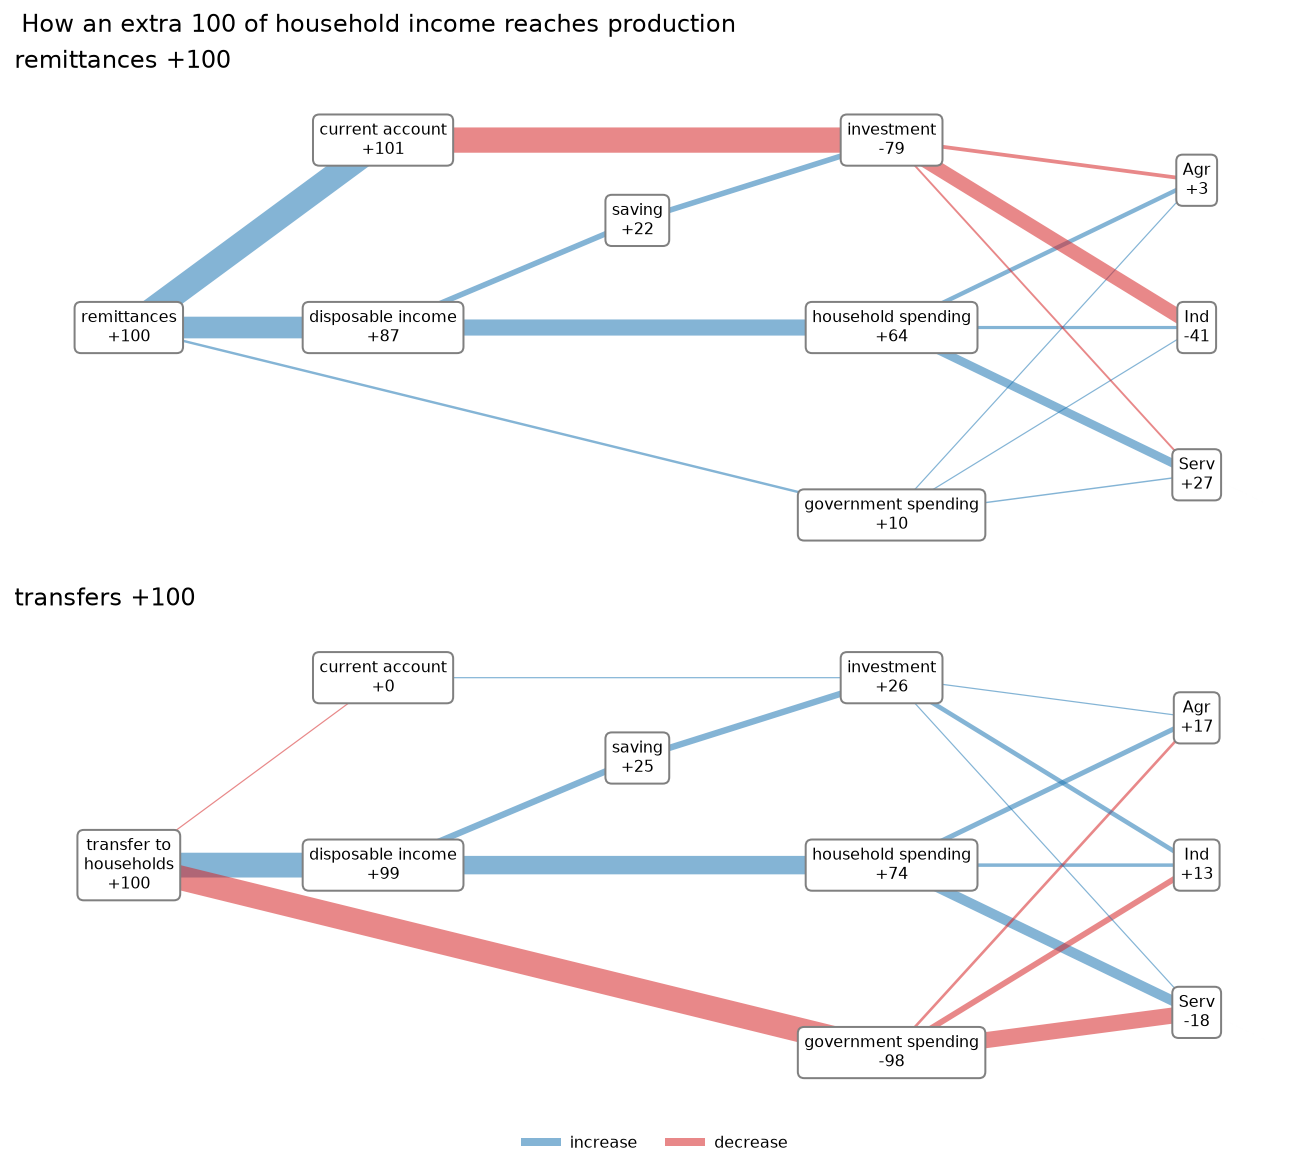

In [17]:
node_positions = {"shock": (0.0, 0.0),
                  "current account": (1.0, 1.4),
                  "disposable income": (1.0, 0.0),
                  "saving": (2.0, 0.8),
                  "investment": (3.0, 1.4),
                  "household spending": (3.0, 0.0),
                  "government spending": (3.0, -1.4),
                  "Agr": (4.2, 1.1),
                  "Ind": (4.2, 0.0),
                  "Serv": (4.2, -1.1)}
shock_names = {"remittances +100": "remittances",
               "transfers +100": "transfer to\nhouseholds"}
sign_colors = {"increase": "C0",
               "decrease": "C3"}

fig, axes = plt.subplots(nrows=2,
                         figsize=(9, 8),
                         dpi=144,
                         layout="constrained")
for ax, (label, result) in zip(axes, results.items()):
    node_values, links = channel_diagram(result)

    for (source, target), value in links.items():
        ax.annotate("",
                    xy=node_positions[target],
                    xytext=node_positions[source],
                    arrowprops={"arrowstyle": "-",
                                "color": sign_colors["increase" if value >= 0 else "decrease"],
                                "linewidth": max(abs(value) / 8, 0.6),
                                "alpha": 0.55,
                                "shrinkA": 0,
                                "shrinkB": 0})

    for node, (x, y) in node_positions.items():
        name = shock_names[label] if node == "shock" else node
        ax.text(x,
                y,
                f"{name}\n{round(node_values[node]):+d}",
                ha="center",
                va="center",
                fontsize=8,
                zorder=3,
                bbox={"boxstyle": "round,pad=0.4", "facecolor": "white", "edgecolor": "0.5"})

    ax.set(xlim=(-0.45, 4.6),
           ylim=(-1.85, 1.85))
    ax.set_title(label,
                 loc="left")
    ax.set_axis_off()

for sign, color in sign_colors.items():
    axes[0].plot([],
                 [],
                 color=color,
                 linewidth=4,
                 alpha=0.55,
                 label=sign)
fig.suptitle("How an extra 100 of household income reaches production",
             x=0.01,
             ha="left")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles=handles,
           labels=labels,
           loc="outside lower center",
           ncol=len(labels),
           frameon=False,
           fontsize=8)
plt.show()

The model's changes by sector are within about 1 of the correction's. In both shocks, the sector that loses output is the one that supplies the spending that falls. Remittances lower investment, and industry supplies 745 of the 1045 of investment goods, so industrial output falls by 41 while higher household consumption lifts agriculture and services. Transfers lower government purchases, and the government buys 2790 of services, more than of any other good, so services lose 18 of output while agriculture and industry grow.

## Authors

- Created by Jesse Grabowski, November 26, 2026

## Watermark

In [18]:
%load_ext watermark
%watermark -n -u -v -iv -m -w -p pytensor

Last updated: Fri, 27 Nov 2026

Python implementation: CPython
Python version       : 3.12.13
IPython version      : 9.18.1

pytensor: 3.3.8

Compiler    : Clang 19.1.7 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

cge_modeling: 0.0.7.dev15+g93cb61e4e.d20261120
matplotlib  : 3.11.2
numpy       : 2.3.5
pandas      : 3.1.1

Watermark: 2.6.0

